# Exercises XP Ninja: Guided Student Notebook

This guided notebook follows the **exercises on the platform**. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points are included only when a concept is important for intuition or transfer to other AI topics.

## Reference from the exercises

**What you will learn**  
- Implement state-of-the-art techniques to solve complex machine learning problems.
- Understand and apply advanced optimization methods for deep learning.
- Build and fine tune large scale models for real world applications.
- Explore cutting edge research areas like generative models and reinforcement learning.
- Develop strategies to handle imbalanced datasets and improve model robustness.

**What you will create**  
A deep learning model optimized using learning rate scheduling and gradient clipping. A generative model to create synthetic data. A reinforcement learning agent for a specific task. A robust model trained on an imbalanced dataset using SMOTE or focal loss. A comparison of performance before and after advanced strategies.

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**), choose **Runtime → Change runtime type → T4 GPU** (it also runs on a CPU, just slower), and run the cells from top to bottom. The first cell installs `imbalanced-learn` (SMOTE/ADASYN) and `gymnasium` (CartPole) if they are missing. All datasets are downloaded by the code. Seeds are fixed, so the results can be repeated (on a GPU the last decimals can change a little).

**Note on the structure:** the platform has 5 exercises, but the Colab template skips **Exercise 3 (Reinforcement Learning Agent)**. I added it in its platform position, so the template's "Exercise 3: Imbalanced" and "Exercise 4: Robustness" are numbered **4** and **5** here, as on the platform.

**How to read this notebook:** before every code cell there is a short **"What this cell does"** note, the code has comments on the important lines, and after key outputs there is a **"What this shows"** note.

**What this cell does:** installs the two extra libraries only if they are not installed yet (`pip -q` = quiet). On Colab, `gymnasium` and `imbalanced-learn` are usually already there, so this is fast.

In [1]:
import importlib, subprocess, sys
for pkg, mod in [("imbalanced-learn", "imblearn"), ("gymnasium", "gymnasium")]:
    if importlib.util.find_spec(mod) is None:                # not installed -> install it
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
print("extra packages ready")

extra packages ready


## Exercise 1: Advanced Optimization Techniques for Deep Learning

**As stated in the exercises**  
Objective. Improve model training stability and convergence using advanced optimization techniques.  
Instructions. Choose a deep learning model such as a CNN or RNN and a dataset such as CIFAR 10 or IMDB. Implement learning rate scheduling such as cosine annealing or step decay during training. Apply gradient clipping to prevent exploding gradients. Compare training stability and convergence with and without these techniques. Write a short analysis of how these techniques improve training.

**Guidance**  
Use CIFAR 10 with a small CNN for quick runs. Compare baseline vs scheduled learning rate and gradient clipping. Track training and validation curves.

**Learning point**  
Learning rate schedules reduce the step size as training progresses which helps convergence near minima. Cosine schedules can give sharper early progress. Gradient clipping caps update magnitude to prevent unstable jumps, especially in RNNs or deep CNNs.

**What this cell does (PREFILLED):** loads the full CIFAR-10 dataset: 50,000 training and 10,000 test colour images of 32×32 pixels (shape `(N, 32, 32, 3)`), in 10 classes. The pixels are scaled to 0–1, and the labels become one-hot vectors of length 10.

In [2]:
# PREFILLED: just execute
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)

# CIFAR-10 data
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

(x_tr, y_tr), (x_te, y_te) = cifar10.load_data()
x_tr = x_tr.astype("float32")/255.0
x_te = x_te.astype("float32")/255.0
y_tr_oh = to_categorical(y_tr, 10)
y_te_oh = to_categorical(y_te, 10)

x_tr.shape, y_tr_oh.shape, x_te.shape, y_te_oh.shape

I0000 00:00:1794919471.471012  286184 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794919471.507345  286184 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794919472.304574  286184 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


((50000, 32, 32, 3), (50000, 10), (10000, 32, 32, 3), (10000, 10))

**What this cell does (PREFILLED):** defines a small CNN and trains a **baseline** for 3 epochs.
- `Conv2D(32, 3, padding="same", activation="relu")`: 32 filters of size 3×3 slide over the image and each one learns a local pattern (edge, colour blob…). `padding="same"` keeps 32×32.
- `MaxPooling2D()` keeps the maximum of every 2×2 window, so the size is halved (32→16→8).
- `Flatten` → `Dense(128)` → `Dense(10, softmax)` turns the features into 10 class probabilities.
- The two optimization tools of this exercise are **arguments of the optimizer**: `Adam(learning_rate=lr, clipnorm=..., clipvalue=...)`.
  - `learning_rate` can be a fixed number **or a schedule object** that changes the step size at every training step.
  - `clipnorm=1.0` rescales the gradient of each weight tensor whenever its length (L2 norm) is above 1.0. `clipvalue` instead cuts every single gradient value to [−v, v]. Either way, one bad batch cannot cause a huge jump.

In [3]:
# PREFILLED: just execute
def build_cnn(clipnorm=None, clipvalue=None, lr=1e-3):
    inputs = layers.Input(shape=(32,32,3))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)                       # 32 -> 16
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)                       # 16 -> 8
    x = layers.Flatten()(x)                            # 8*8*64 = 4096 numbers
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = models.Model(inputs, outputs)
    opt = tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=clipnorm, clipvalue=clipvalue)  # lr may be a schedule
    model.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])
    return model

tf.keras.utils.set_random_seed(7)
baseline = build_cnn()
hist_base = baseline.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=3, batch_size=128, verbose=2)

Epoch 1/3


352/352 - 4s - 10ms/step - accuracy: 0.4454 - loss: 1.5559 - val_accuracy: 0.5644 - val_loss: 1.2397


Epoch 2/3


352/352 - 3s - 8ms/step - accuracy: 0.5946 - loss: 1.1590 - val_accuracy: 0.6168 - val_loss: 1.0806


Epoch 3/3


352/352 - 3s - 8ms/step - accuracy: 0.6463 - loss: 1.0161 - val_accuracy: 0.6526 - val_loss: 1.0041


**What this cell does:** runs the comparison. Three models with the **same architecture, seed, data and number of epochs (8)**:
1. **Baseline:** constant learning rate 1e-3, no clipping.
2. **Cosine + clipping:** `CosineDecay(initial_learning_rate=2e-3, decay_steps=total_steps)` starts with a bigger step (2e-3) and lowers it smoothly along a cosine curve to almost 0 at the end of training. `clipnorm=1.0` is added.
   `total_steps` = batches per epoch × epochs = ceil(45,000 / 128) × 8, because a schedule counts **optimizer steps (batches)**, not epochs.
3. **Step decay + clipping:** a `LearningRateScheduler` callback runs at the start of each epoch and calls `step_decay(epoch, lr)`. Here it halves the learning rate every 3 epochs (2e-3 → 1e-3 → 5e-4), with `clipnorm=1.0`.

I also record the learning rate actually used in every epoch, to plot the schedules.

In [4]:
# To-Do: implement a learning rate schedule and train with gradient clipping
import math, pandas as pd
EPOCHS, BS = 8, 128
steps_per_epoch = math.ceil(len(x_tr) * 0.9 / BS)           # 90% of the data is used for training
total_steps = steps_per_epoch * EPOCHS

# Option 1: use tf.keras.optimizers.schedules.CosineDecay with an initial lr
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(initial_learning_rate=2e-3, decay_steps=total_steps)

# Option 2: step decay via a callback
def step_decay(epoch, lr):
    return 2e-3 * (0.5 ** (epoch // 3))                       # epochs 0-2: 2e-3, 3-5: 1e-3, 6-7: 5e-4
cb = tf.keras.callbacks.LearningRateScheduler(step_decay)

runs = {}
tf.keras.utils.set_random_seed(7)
m = build_cnn(lr=1e-3)                                         # 1) baseline
runs["baseline (lr 1e-3)"] = m.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=EPOCHS, batch_size=BS, verbose=2).history
runs["baseline (lr 1e-3)"]["lr"] = [1e-3] * EPOCHS
res_base = m.evaluate(x_te, y_te_oh, verbose=0)

tf.keras.utils.set_random_seed(7)
model_sched = build_cnn(lr=lr_schedule, clipnorm=1.0)          # 2) cosine + clipping
runs["cosine 2e-3 + clipnorm 1.0"] = model_sched.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=EPOCHS, batch_size=BS, verbose=2).history
runs["cosine 2e-3 + clipnorm 1.0"]["lr"] = [float(lr_schedule(e * steps_per_epoch)) for e in range(EPOCHS)]
res_cos = model_sched.evaluate(x_te, y_te_oh, verbose=0)

tf.keras.utils.set_random_seed(7)
model_clip = build_cnn(clipnorm=1.0, lr=2e-3)                   # 3) step decay (callback) + clipping
runs["step decay + clipnorm 1.0"] = model_clip.fit(x_tr, y_tr_oh, validation_split=0.1, epochs=EPOCHS, batch_size=BS,
                                                   callbacks=[cb], verbose=2).history
runs["step decay + clipnorm 1.0"]["lr"] = [step_decay(e, None) for e in range(EPOCHS)]
res_step = model_clip.evaluate(x_te, y_te_oh, verbose=0)

summary_opt = pd.DataFrame({
    name: {"best val acc": max(h["val_accuracy"]), "final val acc": h["val_accuracy"][-1],
           "final train acc": h["accuracy"][-1], "final val loss": h["val_loss"][-1],
           "min val loss": min(h["val_loss"])}
    for name, h in runs.items()}).T
summary_opt["test acc"] = [res_base[1], res_cos[1], res_step[1]]
summary_opt["test loss"] = [res_base[0], res_cos[0], res_step[0]]
print(summary_opt.round(4).to_string())

Epoch 1/8


352/352 - 4s - 10ms/step - accuracy: 0.4454 - loss: 1.5559 - val_accuracy: 0.5644 - val_loss: 1.2397


Epoch 2/8


352/352 - 3s - 8ms/step - accuracy: 0.5946 - loss: 1.1590 - val_accuracy: 0.6168 - val_loss: 1.0806


Epoch 3/8


352/352 - 3s - 8ms/step - accuracy: 0.6463 - loss: 1.0161 - val_accuracy: 0.6526 - val_loss: 1.0041


... (39 outputs left out)

352/352 - 3s - 10ms/step - accuracy: 0.7778 - loss: 0.6455 - val_accuracy: 0.6976 - val_loss: 0.9026 - learning_rate: 5.0000e-04


Epoch 8/8


352/352 - 3s - 10ms/step - accuracy: 0.7910 - loss: 0.6099 - val_accuracy: 0.6986 - val_loss: 0.9055 - learning_rate: 5.0000e-04


                            best val acc  final val acc  final train acc  final val loss  min val loss  test acc  test loss
baseline (lr 1e-3)                0.6842         0.6804           0.7617          0.9454        0.9170    0.6737     0.9629
cosine 2e-3 + clipnorm 1.0        0.7094         0.7094           0.7890          0.8485        0.8485    0.7071     0.8620
step decay + clipnorm 1.0         0.6986         0.6986           0.7910          0.9055        0.9026    0.6947     0.9077


**To-Do:** Plot two figures. Figure 1 shows training and validation accuracy per epoch for baseline and your improved run. Figure 2 shows training and validation loss per epoch. Explain in 3 to 5 sentences what changed.

**What this cell does:** Figure 1 = accuracy, Figure 2 = loss (dashed = training, solid = validation), and a small third plot with the learning rate used in each epoch.

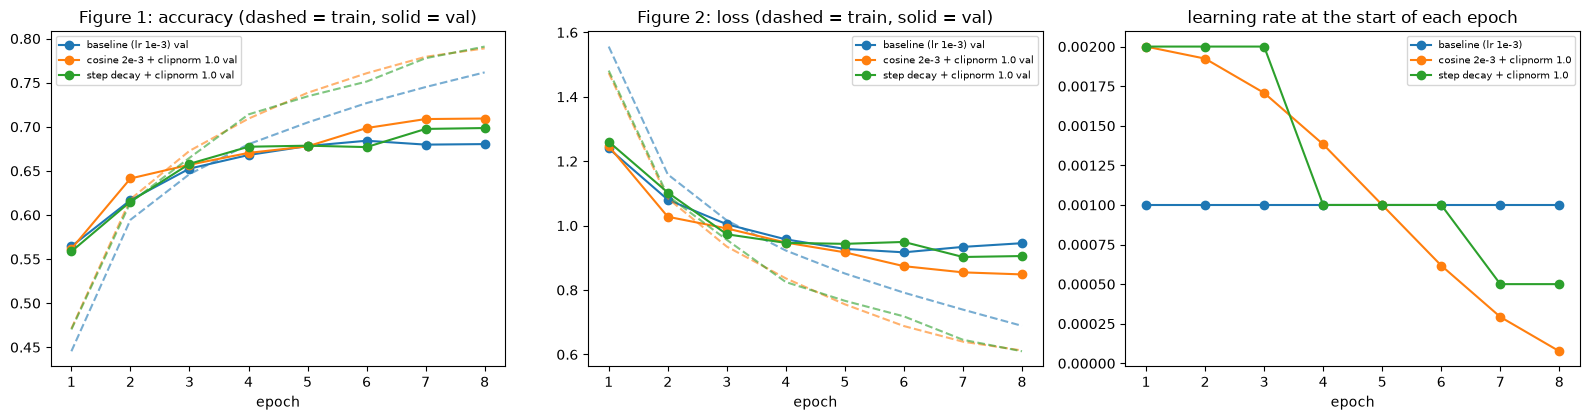

In [5]:
ep = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for name, h in runs.items():
    l, = axes[0].plot(ep, h["val_accuracy"], marker="o", label=f"{name} val")
    axes[0].plot(ep, h["accuracy"], ls="--", color=l.get_color(), alpha=0.6)
    axes[1].plot(ep, h["val_loss"], marker="o", color=l.get_color(), label=f"{name} val")
    axes[1].plot(ep, h["loss"], ls="--", color=l.get_color(), alpha=0.6)
    axes[2].plot(ep, h["lr"], marker="o", color=l.get_color(), label=name)
axes[0].set_title("Figure 1: accuracy (dashed = train, solid = val)")
axes[1].set_title("Figure 2: loss (dashed = train, solid = val)")
axes[2].set_title("learning rate at the start of each epoch")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**My answer:** All three runs used the same CNN, seed and 8 epochs, so the only differences are the learning-rate schedule and the clipping.
- **Convergence:** with a constant learning rate, the baseline's validation accuracy stopped improving after about epoch 4–5 (best 0.684, final 0.680), and its validation loss went back **up** at the end (minimum 0.917, final 0.945). **Cosine decay + clipping** kept improving to the last epoch and reached the best results: validation accuracy 0.709, validation loss 0.849, **test accuracy 0.707 vs 0.674** for the baseline (test loss 0.862 vs 0.963). Step decay + clipping came second (test accuracy 0.695).
- **Why:** a larger learning rate early (2e-3) moves fast while the loss is high. The shrinking learning rate at the end makes smaller, more careful steps, so the model settles into a minimum instead of bouncing around it, which is why the cosine curves are the smoothest at the end. In the step-decay run you can see a small jump in validation accuracy right after each halving.
- **Gradient clipping** (`clipnorm=1.0`) is a safety net. With this small CNN, Adam and normalized images the gradients never really exploded, so most of the gain here comes from the schedule. Clipping matters most for RNNs, very deep networks or high learning rates, where one huge gradient can ruin the weights.
- **Overfitting:** all three runs show training accuracy above validation accuracy by the end (a gap of 0.08–0.09 for each), so the schedule improves convergence but does not replace regularization such as dropout or augmentation.

**What this cell does:** frees the CIFAR-10 arrays (about 0.7 GB) before the next exercises. `gc.collect()` asks Python to release the memory now.

In [6]:
import gc
del x_tr, x_te, y_tr_oh, y_te_oh, baseline, m, model_sched, model_clip
gc.collect(); tf.keras.backend.clear_session()
print("CIFAR-10 arrays released")

CIFAR-10 arrays released


## Exercise 2: Building a Generative Model

**As stated in the exercises**  
Objective. Create a generative model to produce synthetic data.  
Instructions. Choose an architecture such as a GAN or a VAE. Train on a dataset such as MNIST or CelebA. Evaluate sample quality using FID or visual inspection. Experiment with architectures such as DCGAN or loss choices. Write a short reflection on challenges and applications.

**Guidance**  
A VAE on MNIST is simpler to train than a GAN. Implement encoder and decoder with a reparameterization step. Use binary cross entropy reconstruction and KL regularization.

**Learning point**  
VAEs learn a latent distribution that supports interpolation and sampling. GANs can yield sharper images but are sensitive to instability and mode collapse.

**What this cell does (PREFILLED):** loads MNIST, scales the pixels to 0–1 and adds a channel axis with `np.expand_dims(..., -1)`: (60000, 28, 28) → (60000, 28, 28, 1), because `Conv2D` layers expect a channel dimension.

In [7]:
# PREFILLED: just execute
from tensorflow.keras.datasets import mnist
(xm_tr, ym_tr), (xm_te, ym_te) = mnist.load_data()
xm_tr = xm_tr.astype("float32")/255.0
xm_te = xm_te.astype("float32")/255.0
xm_tr = np.expand_dims(xm_tr, -1)
xm_te = np.expand_dims(xm_te, -1)
xm_tr.shape, xm_te.shape

((60000, 28, 28, 1), (10000, 28, 28, 1))

**How a VAE works (before the code):**
- The **encoder** compresses an image into two vectors of length `latent_dim`: `z_mean` (μ) and `z_logvar` (log σ²). Together they describe a small cloud (a normal distribution) in "latent space" where this image lives.
- **Reparameterization trick:** I sample `z = μ + σ·ε` with ε ~ N(0, 1). The randomness is in ε only, so gradients can still flow back through μ and σ.
- The **decoder** turns `z` back into a 28×28 image.
- **Loss = reconstruction + KL:**
  - *reconstruction* = binary crossentropy between the input pixels and the decoded pixels, summed over the 784 pixels ("does the output look like the input?"),
  - *KL divergence* = how far each image's cloud N(μ, σ²) is from the standard normal N(0, 1). This pulls all codes into one smooth region, so **any** random point from N(0, 1) decodes into a plausible digit.
- **Generating new digits:** sample z from N(0, 1) and run only the decoder.

**What this cell does:** builds the encoder and decoder as two Keras models, plus a training step written by hand with `tf.GradientTape`. The tape records the forward pass, so `tape.gradient(loss, weights)` can compute the gradients, and `optimizer.apply_gradients` updates the weights. This is exactly what `model.fit` does internally, written out because the VAE loss needs both the encoder and the decoder outputs.

In [8]:
# To-Do: implement a small VAE
def build_conv_vae(latent_dim=16):
    # Encoder: Input (28,28,1) -> Conv/Dense -> z_mean, z_logvar
    enc_in = layers.Input(shape=(28, 28, 1))
    h = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(enc_in)   # -> 14x14x32
    h = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)        # -> 7x7x64
    h = layers.Flatten()(h)
    h = layers.Dense(128, activation="relu")(h)
    z_mean = layers.Dense(latent_dim, name="z_mean")(h)
    z_logvar = layers.Dense(latent_dim, name="z_logvar")(h)
    encoder = models.Model(enc_in, [z_mean, z_logvar], name="encoder")
    # Decoder: Dense/ConvTranspose -> output logits
    dec_in = layers.Input(shape=(latent_dim,))
    g = layers.Dense(7 * 7 * 64, activation="relu")(dec_in)
    g = layers.Reshape((7, 7, 64))(g)
    g = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(g)  # -> 14x14
    g = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(g)  # -> 28x28
    logits = layers.Conv2DTranspose(1, 3, padding="same")(g)                           # 1 channel, raw scores
    decoder = models.Model(dec_in, logits, name="decoder")
    return encoder, decoder

def build_dense_vae(latent_dim=2):
    # simpler architecture for the experiment: only Dense layers
    enc_in = layers.Input(shape=(28, 28, 1))
    h = layers.Dense(256, activation="relu")(layers.Flatten()(enc_in))
    encoder = models.Model(enc_in, [layers.Dense(latent_dim)(h), layers.Dense(latent_dim)(h)], name="encoder_dense")
    dec_in = layers.Input(shape=(latent_dim,))
    g = layers.Dense(256, activation="relu")(dec_in)
    logits = layers.Reshape((28, 28, 1))(layers.Dense(784)(g))
    return encoder, models.Model(dec_in, logits, name="decoder_dense")

def reparameterize(z_mean, z_logvar):
    eps = tf.random.normal(tf.shape(z_mean))              # eps ~ N(0, 1)
    return z_mean + tf.exp(0.5 * z_logvar) * eps          # z = mu + sigma * eps

def train_vae(encoder, decoder, epochs=5, batch_size=128, beta=1.0, lr=1e-3):
    opt = tf.keras.optimizers.Adam(lr)
    weights = encoder.trainable_weights + decoder.trainable_weights
    @tf.function                                           # compile the step into a fast graph
    def train_step(x):
        with tf.GradientTape() as tape:
            z_mean, z_logvar = encoder(x, training=True)
            z = reparameterize(z_mean, z_logvar)
            logits = decoder(z, training=True)
            # reconstruction: binary crossentropy summed over the 784 pixels, averaged over the batch
            recon = tf.reduce_mean(tf.reduce_sum(
                tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=logits), axis=[1, 2, 3]))
            # KL( N(mu, sigma^2) || N(0, 1) ), summed over the latent dimensions
            kl = tf.reduce_mean(tf.reduce_sum(
                -0.5 * (1 + z_logvar - tf.square(z_mean) - tf.exp(z_logvar)), axis=1))
            loss = recon + beta * kl                       # Define VAE loss = recon_loss + KL
        grads = tape.gradient(loss, weights)
        opt.apply_gradients(zip(grads, weights))
        return loss, recon, kl
    ds = tf.data.Dataset.from_tensor_slices(xm_tr).shuffle(60000, seed=7).batch(batch_size)
    log = []
    for epoch in range(epochs):
        tot = np.zeros(3); n = 0
        for xb in ds:
            tot += np.array([t.numpy() for t in train_step(xb)]); n += 1
        log.append(tot / n)
        print(f"epoch {epoch+1}: loss {log[-1][0]:.2f} = recon {log[-1][1]:.2f} + KL {log[-1][2]:.2f}")
    return np.array(log)

tf.keras.utils.set_random_seed(7)
latent_dim = 16
encoder, decoder = build_conv_vae(latent_dim)
print("Training the convolutional VAE (latent_dim=16):")
vae_log = train_vae(encoder, decoder, epochs=5)

Training the convolutional VAE (latent_dim=16):


epoch 1: loss 183.46 = recon 172.74 + KL 10.72


epoch 2: loss 117.23 = recon 97.43 + KL 19.79


epoch 3: loss 109.01 = recon 88.47 + KL 20.54


epoch 4: loss 106.31 = recon 85.56 + KL 20.74


epoch 5: loss 104.77 = recon 83.85 + KL 20.93


**What this shows:** the total loss fell from 183.5 to 104.8 in 5 epochs. The **reconstruction** part fell from 172.7 to 83.9, so the decoder rebuilds digits much better. The **KL** part *rose* from 10.7 to 20.9. That is expected: at the start the codes are squeezed close to N(0, 1) and carry little information, and as training goes on the encoder spends some "KL budget" to store more detail about each digit. The two terms pull against each other, which is the VAE trade-off.

**To-Do:** Display a grid of generated digits and comment on sample diversity and blur. If you choose a GAN instead, show a grid of samples and describe any instability you observed.

**What this cell does:**
- **Row block 1, reconstructions:** 10 test images (top) and the VAE's reconstruction of each (bottom). The encoder sees the image and I decode `z_mean`. This checks that the model learned to compress and rebuild digits.
- **Grid 2, new digits:** 64 random vectors z ~ N(0, 1) passed through the decoder only. `tf.sigmoid(logits)` turns the raw outputs into pixel values between 0 and 1.

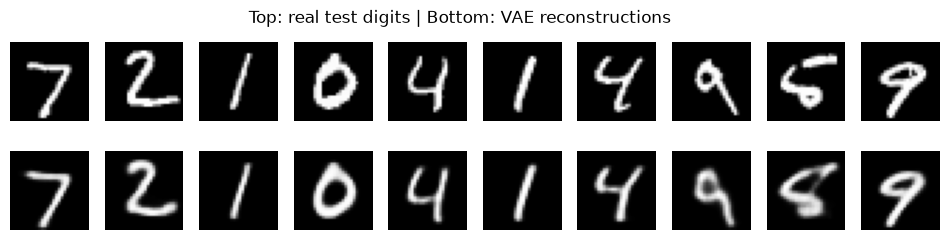

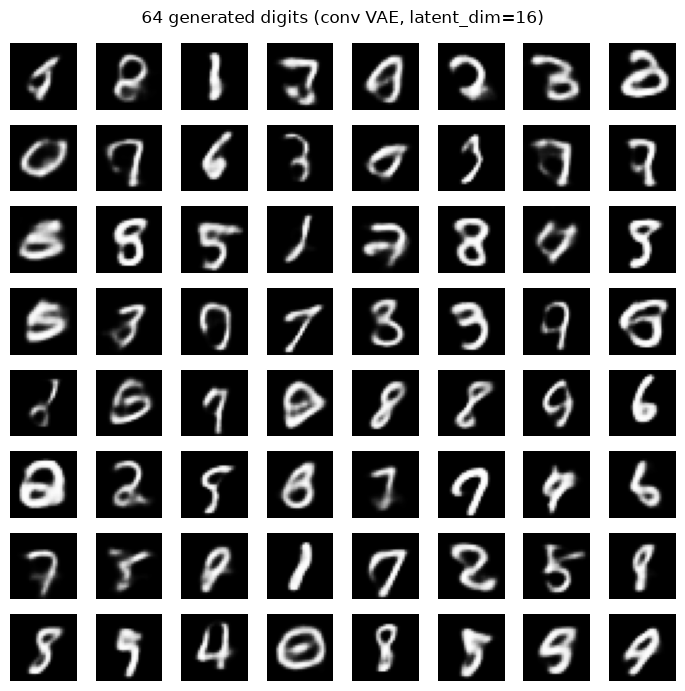

In [9]:
tf.keras.utils.set_random_seed(1)
# reconstructions of unseen test digits
zm, _ = encoder(xm_te[:10], training=False)
recon_imgs = tf.sigmoid(decoder(zm, training=False)).numpy()
plt.figure(figsize=(12, 2.6))
for i in range(10):
    plt.subplot(2, 10, i + 1); plt.imshow(xm_te[i, :, :, 0], cmap="gray"); plt.axis("off")
    plt.subplot(2, 10, 10 + i + 1); plt.imshow(recon_imgs[i, :, :, 0], cmap="gray"); plt.axis("off")
plt.suptitle("Top: real test digits | Bottom: VAE reconstructions"); plt.show()

# brand-new digits sampled from the latent space
z_new = tf.random.normal((64, latent_dim))                 # 64 random points from N(0, 1)
gen = tf.sigmoid(decoder(z_new, training=False)).numpy()   # decoder only
plt.figure(figsize=(7, 7))
for i in range(64):
    plt.subplot(8, 8, i + 1); plt.imshow(gen[i, :, :, 0], cmap="gray"); plt.axis("off")
plt.suptitle("64 generated digits (conv VAE, latent_dim=16)"); plt.tight_layout(); plt.show()

**Evaluating the samples without FID.** FID needs a large pre-trained Inception network and thousands of samples, which is heavy for this exercise. Instead I use a cheaper check built on the same idea: train a quick MNIST classifier, then let it label 1,000 generated digits.
- **Quality:** a recognizable digit should get a **confident** prediction (a high maximum softmax probability).
- **Diversity:** a good generator produces **all 10 digits** in roughly equal numbers. Mode collapse would show up as one or two dominant classes.

**What this cell does:** trains a small CNN classifier for 2 epochs on real MNIST, then measures confidence and class spread on the real test digits (the reference) and on the generated digits.

In [10]:
tf.keras.utils.set_random_seed(7)
judge = models.Sequential([layers.Input(shape=(28, 28, 1)),
                           layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
                           layers.Flatten(), layers.Dense(128, activation="relu"),
                           layers.Dense(10, activation="softmax")])
judge.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])  # integer labels
judge.fit(xm_tr, ym_tr, epochs=2, batch_size=128, verbose=0)
print("judge accuracy on real test digits:", round(judge.evaluate(xm_te, ym_te, verbose=0)[1], 4))

def judge_samples(images):
    p = judge.predict(images, verbose=0)                     # (N, 10) probabilities
    counts = np.bincount(p.argmax(1), minlength=10)          # how many of each predicted digit
    return p.max(1).mean(), (p.max(1) > 0.9).mean(), counts

z_eval = tf.random.normal((1000, latent_dim), seed=11)
gen_eval = tf.sigmoid(decoder(z_eval, training=False)).numpy()
for name, imgs in [("real test digits", xm_te[:1000]), ("conv VAE samples", gen_eval)]:
    conf, share90, counts = judge_samples(imgs)
    print(f"{name:18s} mean confidence {conf:.3f} | share > 0.9: {share90:.3f} | class counts {counts.tolist()}")

judge accuracy on real test digits: 0.9823
real test digits   mean confidence 0.974 | share > 0.9: 0.919 | class counts [87, 124, 117, 110, 109, 84, 85, 99, 92, 93]


conv VAE samples   mean confidence 0.760 | share > 0.9: 0.358 | class counts [90, 58, 137, 129, 116, 78, 94, 87, 91, 120]


**What this shows:** the generated digits are recognizable but less clean than real ones. The judge classifier (98.2% accurate on real digits) is on average **76.0% confident** on VAE samples vs **97.4%** on real test digits, and only **35.8%** of the samples get a confidence above 0.9 (91.9% for real digits). **Diversity is good:** all 10 digits appear, between 58 (digit 1) and 137 (digit 2) times out of 1,000, so there is no mode collapse. In the grid, most samples are clearly digits, some are ambiguous (for example 4/9 or 3/5 mixtures), and almost all are **blurry** around the edges. That blur is typical of VAEs: the pixel-wise crossentropy loss rewards an "average" of the plausible images when the model is unsure.

**Experiment: a different architecture.** I train a simpler **Dense-only VAE with a 2-dimensional latent space** for the same 5 epochs. With only 2 latent numbers, I can draw the whole latent space as a grid: each grid point (z1, z2) is decoded into a digit. This shows the smooth "map" of digits that a VAE learns.

Training the dense VAE (latent_dim=2):


epoch 1: loss 205.72 = recon 196.80 + KL 8.92


epoch 2: loss 170.70 = recon 165.70 + KL 5.01


epoch 3: loss 166.24 = recon 161.07 + KL 5.17


epoch 4: loss 163.79 = recon 158.54 + KL 5.25


epoch 5: loss 162.24 = recon 156.94 + KL 5.30


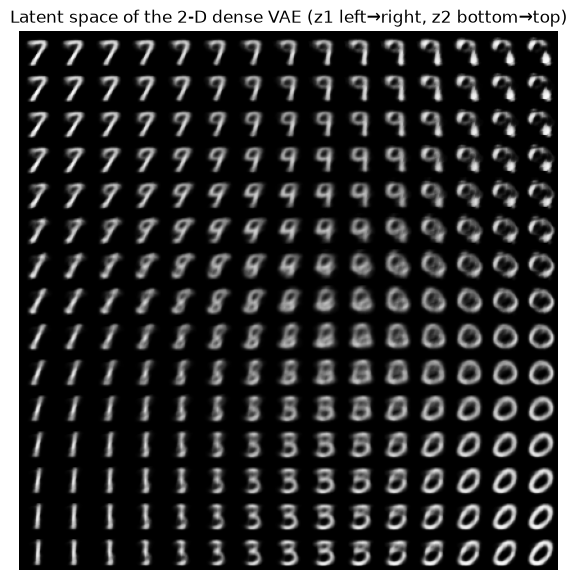

dense 2-D VAE samples: mean confidence 0.594 | share > 0.9: 0.142 | class counts [141, 209, 52, 58, 55, 31, 178, 30, 35, 211]
final loss -> conv VAE (16-D): 104.77 | dense VAE (2-D): 162.24


In [11]:
tf.keras.utils.set_random_seed(7)
enc2, dec2 = build_dense_vae(latent_dim=2)
print("Training the dense VAE (latent_dim=2):")
vae2_log = train_vae(enc2, dec2, epochs=5)

# decode a 15x15 grid of latent points between -2.5 and 2.5
n, grid_vals = 15, np.linspace(-2.5, 2.5, 15)
canvas = np.zeros((28 * n, 28 * n))
for i, z2 in enumerate(grid_vals[::-1]):
    for j, z1 in enumerate(grid_vals):
        img = tf.sigmoid(dec2(np.array([[z1, z2]], dtype="float32"), training=False)).numpy()[0, :, :, 0]
        canvas[i*28:(i+1)*28, j*28:(j+1)*28] = img
plt.figure(figsize=(7, 7)); plt.imshow(canvas, cmap="gray"); plt.axis("off")
plt.title("Latent space of the 2-D dense VAE (z1 left→right, z2 bottom→top)"); plt.show()

gen2 = tf.sigmoid(dec2(tf.random.normal((1000, 2), seed=11), training=False)).numpy()
conf2, share2, counts2 = judge_samples(gen2)
print(f"dense 2-D VAE samples: mean confidence {conf2:.3f} | share > 0.9: {share2:.3f} | class counts {counts2.tolist()}")
print(f"final loss -> conv VAE (16-D): {vae_log[-1][0]:.2f} | dense VAE (2-D): {vae2_log[-1][0]:.2f}")

**What this shows:** the 2-D latent map shows that the VAE organizes the digits **smoothly**: moving across the grid, 1s turn into 3s/5s and then into 0s, and 7s turn into 9s. Every point decodes into something digit-like, which is exactly what the KL term is for. But 2 latent numbers are too few to store all 10 digit shapes. The final loss is much worse (162.2 vs 104.8 for the conv VAE with 16 dimensions), the judge is only 59.4% confident on average, and diversity collapses toward a few digits (1: 209, 9: 211, 0: 141, 6: 178, but only 30 sevens and 31 fives out of 1,000). So in this experiment the **convolutional encoder/decoder with a larger latent space is clearly the better architecture**. The small latent space is only useful for visualization.

**My reflection (challenges and applications of generative models):** The main challenge of generative models is that there is no single "correct answer" to compare with, so quality is hard to measure. FID needs a big pretrained network, and visual inspection is subjective, which is why I used a classifier as a cheaper proxy for quality and diversity. Each family also has its own problem: VAEs train stably but give blurry images (my samples were only 76% "convincing" to the classifier), while GANs give sharper images but are unstable and can suffer mode collapse, where they produce only a few kinds of output. Generative models also need careful balancing, here between reconstruction and KL, and a lot of compute for realistic, high-resolution data. Their applications include creating synthetic data to augment small or private datasets (medical images, fraud cases), anomaly detection (inputs that reconstruct badly are suspicious), image denoising and inpainting, drug and molecule design, and today's image, audio and text generators.

![image.png](https://github.com/user-attachments/assets/d63da82c-2d11-48cf-bd70-7cc68bd90722)

## Exercise 3: Reinforcement Learning Agent *(added: not in the Colab template)*

**As stated in the exercises**  
Objective. Train a reinforcement learning agent to solve a specific task.  
Instructions. Choose a reinforcement learning environment (e.g., OpenAI Gym's CartPole, LunarLander, or a custom environment). Implement a reinforcement learning algorithm (e.g., Deep Q-Network (DQN), Proximal Policy Optimization (PPO), or A2C). Train the agent to achieve a high score or complete the task efficiently. Experiment with hyperparameters (e.g., discount factor, learning rate) and reward shaping to improve the agent's performance. Write a short summary (3-5 sentences) on the challenges of training reinforcement learning agents and their real-world applications.

**The task: CartPole-v1** (from `gymnasium`, the maintained version of OpenAI Gym). A pole stands on a cart, and at every time step the agent pushes the cart **left (0) or right (1)**.
- **State** (what the agent sees): 4 numbers, the cart position, cart velocity, pole angle and pole angular velocity.
- **Reward:** +1 for every step the pole stays up. The episode ends when the pole falls more than 12°, the cart leaves the track, or after **500 steps** (the maximum score).

**The algorithm: Deep Q-Network (DQN).**
- A neural network estimates **Q(s, a)** = the total future reward expected after taking action a in state s and playing well afterwards. The agent picks the action with the highest Q.
- **Training target (Bellman equation):** Q(s, a) ≈ r + γ · max over a' of Q_target(s', a'). Here **γ (gamma)** is the **discount factor**: how much future rewards count compared with the immediate one.
- **ε-greedy exploration:** with probability ε the agent takes a random action, so it tries new things. ε starts at 1.0 and decays to 0.05.
- **Replay buffer:** past transitions (s, a, r, s', done) are stored, and the network trains on random mini-batches of them. This breaks the strong correlation between consecutive steps.
- **Target network:** a copy of the Q-network that is updated only every 500 steps, so the training target does not move at every step.

**What this cell does:** defines the DQN agent and a `train_dqn` function.
- `make_qnet`: `Input(4)` → `Dense(64, relu)` → `Dense(64, relu)` → `Dense(2)`: one Q-value per action, linear output (no activation), because Q-values are unbounded numbers.
- `learn` (one gradient step, `@tf.function` for speed): computes the Bellman target with the target network, takes the predicted Q of the action actually played (`tf.gather` with batch indices), and minimizes the **Huber loss** between them. Huber behaves like MSE for small errors and like the absolute error for big ones, which is more stable.
- `(1 - done)` removes the future term when the episode really ended (the pole fell). An episode cut at 500 steps (`truncated`) is not a real end, so it keeps the future term.
- `shaping=True` is the reward-shaping experiment: instead of +1 per step, the reward is 1 − |pole angle| / 0.21 rad (the fall limit), so the agent gets more reward for keeping the pole close to vertical. The **score I report is always the original CartPole score** (steps survived), so all runs are comparable.
- Training stops early when the average score over the last 20 episodes is ≥ 475.

In [12]:
import gymnasium as gym
from collections import deque
import random, time

def make_qnet(lr):
    q = models.Sequential([layers.Input(shape=(4,)),
                           layers.Dense(64, activation="relu"),
                           layers.Dense(64, activation="relu"),
                           layers.Dense(2)])                          # Q(s, left), Q(s, right)
    q.compile(optimizer=tf.keras.optimizers.Adam(lr), loss=tf.keras.losses.Huber())
    return q

def train_dqn(gamma=0.99, lr=1e-3, episodes=500, shaping=False, seed=0, verbose=True):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
    env = gym.make("CartPole-v1")
    q, q_target = make_qnet(lr), make_qnet(lr)
    q_target.set_weights(q.get_weights())                           # start as an exact copy
    buffer = deque(maxlen=20000)                                    # replay buffer
    eps, eps_min, eps_decay = 1.0, 0.05, 0.995
    batch, warmup, target_every, step = 64, 1000, 500, 0
    loss_fn, opt = tf.keras.losses.Huber(), q.optimizer

    @tf.function
    def act_greedy(s):
        return tf.argmax(q(s, training=False)[0])                  # action with the highest Q

    @tf.function
    def learn(s, a, r, s2, done):
        q_next = tf.reduce_max(q_target(s2, training=False), axis=1)          # max_a' Q_target(s', a')
        target = r + gamma * q_next * (1.0 - done)                            # Bellman target
        with tf.GradientTape() as tape:
            q_all = q(s, training=True)                                       # (batch, 2)
            q_sa = tf.gather(q_all, a, axis=1, batch_dims=1)                  # Q of the action played
            loss = loss_fn(target, q_sa)
        grads = tape.gradient(loss, q.trainable_weights)
        opt.apply_gradients(zip(grads, q.trainable_weights))
        return loss

    scores, t0 = [], time.time()
    for ep in range(episodes):
        s, _ = env.reset(seed=seed + ep)
        score, done = 0, False
        while not done:
            if random.random() < eps:
                a = env.action_space.sample()                                  # explore
            else:
                a = int(act_greedy(tf.constant(s[None], tf.float32)))          # exploit
            s2, r, terminated, truncated, _ = env.step(a)
            done = terminated or truncated
            score += r                                                         # original score
            if shaping:
                r = 1.0 - abs(s2[2]) / 0.2095                                  # reward upright poles more
            buffer.append((s, a, r, s2, float(terminated)))
            s, step = s2, step + 1
            if len(buffer) >= warmup:
                mb = random.sample(buffer, batch)
                S, A, R, S2, D = map(np.array, zip(*mb))
                learn(tf.constant(S, tf.float32), tf.constant(A, tf.int32), tf.constant(R, tf.float32),
                      tf.constant(S2, tf.float32), tf.constant(D, tf.float32))
            if step % target_every == 0:
                q_target.set_weights(q.get_weights())                          # refresh the target network
        eps = max(eps_min, eps * eps_decay)
        scores.append(score)
        if verbose and (ep + 1) % 50 == 0:
            print(f"  episode {ep+1:3d} | last score {score:5.0f} | avg last 20: {np.mean(scores[-20:]):6.1f} | eps {eps:.2f} | {time.time()-t0:4.0f}s")
        if len(scores) >= 20 and np.mean(scores[-20:]) >= 475:
            if verbose: print(f"  solved: avg of last 20 episodes >= 475 after {ep+1} episodes")
            break
    env.close()
    return q, scores

def evaluate_agent(q, n=10, seed=1000):
    env = gym.make("CartPole-v1"); results = []
    for i in range(n):
        s, _ = env.reset(seed=seed + i); done, score = False, 0
        while not done:
            a = int(np.argmax(q(s[None].astype("float32"), training=False)[0]))   # greedy, no exploration
            s, r, term, trunc, _ = env.step(a); done = term or trunc; score += r
        results.append(score)
    env.close()
    return results

**What this cell does:** trains the main agent (γ = 0.99, learning rate 1e-3, up to 500 episodes), plots its score per episode with a 20-episode moving average, and then tests the trained agent greedily (no random actions, ε = 0) on 10 new episodes.

Main DQN agent: gamma=0.99, lr=1e-3


  episode  50 | last score    19 | avg last 20:   20.1 | eps 0.78 |    1s


  episode 100 | last score    12 | avg last 20:   15.8 | eps 0.61 |    2s


  episode 150 | last score    15 | avg last 20:   21.1 | eps 0.47 |    2s


  episode 200 | last score    98 | avg last 20:  118.9 | eps 0.37 |    7s


  episode 250 | last score    20 | avg last 20:   37.0 | eps 0.29 |    9s


... (2 outputs left out)

  episode 400 | last score    15 | avg last 20:   79.8 | eps 0.13 |   21s


  episode 450 | last score   188 | avg last 20:  105.3 | eps 0.10 |   28s


  episode 500 | last score    53 | avg last 20:   26.6 | eps 0.08 |   30s


greedy test scores (10 new episodes): [131.0, 159.0, 122.0, 136.0, 103.0, 129.0, 157.0, 117.0, 135.0, 111.0] | mean: 130.0


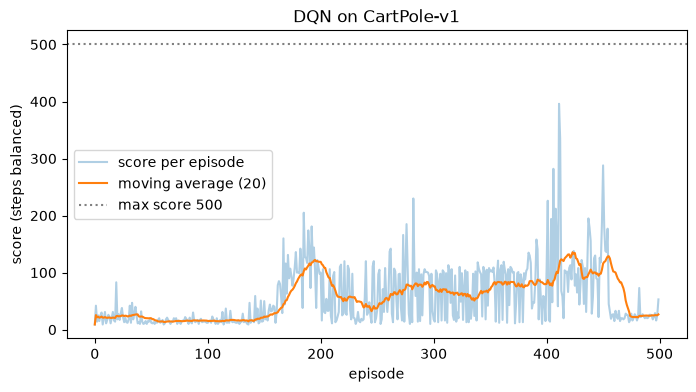

In [13]:
print("Main DQN agent: gamma=0.99, lr=1e-3")
q_main, scores_main = train_dqn(gamma=0.99, lr=1e-3)
eval_main = evaluate_agent(q_main)
print("greedy test scores (10 new episodes):", eval_main, "| mean:", np.mean(eval_main))

def moving_avg(x, k=20):
    return [np.mean(x[max(0, i - k + 1): i + 1]) for i in range(len(x))]
plt.figure(figsize=(8, 4))
plt.plot(scores_main, alpha=0.35, label="score per episode")
plt.plot(moving_avg(scores_main), label="moving average (20)")
plt.axhline(500, color="gray", ls=":", label="max score 500")
plt.xlabel("episode"); plt.ylabel("score (steps balanced)"); plt.title("DQN on CartPole-v1")
plt.legend(); plt.show()

**What this shows:** learning in RL is slow and **noisy**. During the first ~150 episodes the agent mostly acts randomly (ε is still high) and scores about 15–25. Then the score jumps (moving average 118.9 around episode 200), drops again (37.0 at episode 250), and keeps going up and down until episode 500. The best stretch had a moving average of 105.3 at episode 450. The run **did not reach the "solved" level** (average ≥ 475) within 500 episodes. Tested greedily on 10 new episodes, the agent balanced the pole for **130 steps on average** (from 103 to 159), about 6× better than random play (~20), but far from the maximum of 500. These ups and downs are a known weakness of plain DQN: the training targets keep moving as the network changes.

**What this cell does: hyperparameter and reward-shaping experiment.** Each setting below gets the same budget of **300 episodes** (it stops earlier if solved) and seed 0, and each is then tested greedily on the same 10 new episodes. I compare the main setting against a **lower discount factor** (γ = 0.90), a **lower learning rate** (1e-4), and **reward shaping**.

gamma 0.99, lr 1e-3 (main)       done: greedy test mean 95.3


gamma 0.90, lr 1e-3              done: greedy test mean 96.6


gamma 0.99, lr 1e-4              done: greedy test mean 11.1


gamma 0.99, lr 1e-3 + shaping    done: greedy test mean 500.0
                      setting  episodes run  avg score last 20 train  best train score  greedy test mean (10 eps)
   gamma 0.99, lr 1e-3 (main)           300                     91.2             452.0                       95.3
          gamma 0.90, lr 1e-3           300                     87.2             254.0                       96.6
          gamma 0.99, lr 1e-4           300                     11.6              64.0                       11.1
gamma 0.99, lr 1e-3 + shaping           295                    475.8             500.0                      500.0


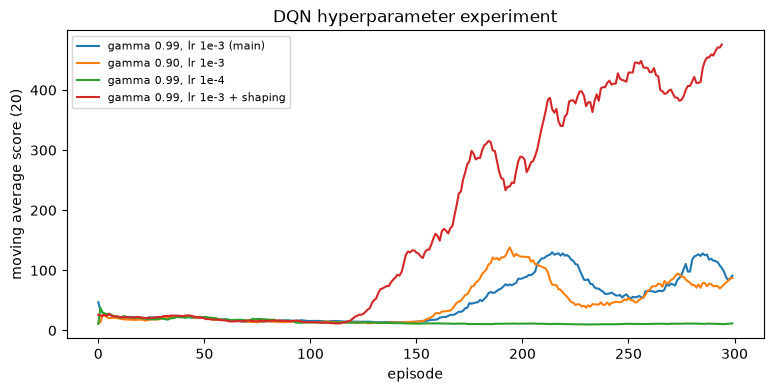

In [14]:
experiments = {"gamma 0.99, lr 1e-3 (main)": dict(gamma=0.99, lr=1e-3),
               "gamma 0.90, lr 1e-3":        dict(gamma=0.90, lr=1e-3),
               "gamma 0.99, lr 1e-4":        dict(gamma=0.99, lr=1e-4),
               "gamma 0.99, lr 1e-3 + shaping": dict(gamma=0.99, lr=1e-3, shaping=True)}
rl_rows, rl_curves = [], {}
for name, kw in experiments.items():
    q_e, sc = train_dqn(episodes=300, verbose=False, **kw)
    ev = evaluate_agent(q_e)
    rl_curves[name] = sc
    rl_rows.append({"setting": name, "episodes run": len(sc), "avg score last 20 train": np.mean(sc[-20:]),
                    "best train score": max(sc), "greedy test mean (10 eps)": np.mean(ev)})
    print(f"{name:32s} done: greedy test mean {np.mean(ev):.1f}")
rl_df = pd.DataFrame(rl_rows)
print(rl_df.round(1).to_string(index=False))

plt.figure(figsize=(9, 4))
for name, sc in rl_curves.items():
    plt.plot(moving_avg(sc), label=name)
plt.xlabel("episode"); plt.ylabel("moving average score (20)"); plt.title("DQN hyperparameter experiment")
plt.legend(fontsize=8); plt.show()

**What this shows:** with the same budget of 300 episodes:
- **Learning rate** mattered most among the plain hyperparameters. With lr = 1e-4 the agent barely learned (greedy test mean 11.1, best training score 64), because the updates were too small for this budget.
- **Discount factor:** γ = 0.90 and γ = 0.99 ended up about the same (greedy test 96.6 vs 95.3). γ = 0.99 reached a higher best training score (452 vs 254). Looking further ahead helps in CartPole because a mistake now makes the pole fall many steps later.
- **Reward shaping was the clear winner.** With a reward of 1 − |pole angle| / 0.21 instead of a flat +1, the agent reached the solved criterion (moving average 475.8) after 295 episodes, and scored the **maximum 500 in all 10 greedy test episodes**. The shaped reward tells the agent *at every step* how close it is to failing, instead of only the delayed signal "the episode ended". That makes the credit-assignment problem much easier.
- Note: these are single runs with one seed. DQN results change a lot between seeds, so a proper comparison would average several seeds.

**My summary (challenges of RL and real-world uses):** Training RL agents is hard because the agent has to discover good behaviour by trial and error from a **delayed and sparse reward**. It also has to balance exploring new actions against exploiting what already works, and its training data keeps changing as its own policy changes. This made my DQN unstable and very sensitive to settings: the main agent's score jumped up and down and never solved CartPole in 500 episodes, a 10× lower learning rate learned almost nothing, and one change to the reward function took the agent from about 95 to a perfect 500. Reward design is powerful but also risky, because an agent will optimize exactly the reward it is given, even when that differs from what we really want. RL is also sample-hungry, so real-world uses usually train in simulators first. Real applications include robotics and control (balancing, grasping, drones), game playing (AlphaGo), recommendation and ad systems, energy optimization in data centres, trading and inventory decisions, and fine-tuning language models from human feedback (RLHF).

## Exercise 4: Handling Imbalanced Datasets *(Exercise 3 in the Colab template)*

**As stated in the exercises**  
Objective. Improve performance on imbalanced datasets using advanced techniques.  
Instructions. Choose an imbalanced dataset such as credit card fraud. Apply SMOTE or ADASYN to balance the data. Train a model with focal loss or weighted cross entropy. Compare precision, recall, and F1 before and after. Write an analysis on the importance of handling imbalance.

**Learning point**  
Accuracy is misleading under class imbalance. Prefer precision, recall, F1, and PR AUC. SMOTE synthesizes minority points and focal loss focuses the objective on hard examples.

**What this cell does (PREFILLED):** creates a synthetic "fraud-like" dataset with `make_classification`: 5,000 rows, 20 features (6 of them informative), and **96% class 0 vs 4% class 1** (`weights=[0.96, 0.04]`). `flip_y=0.005` flips 0.5% of the labels at random, as label noise. The split is stratified 80/20 and the features are standardized (scaler fitted on the training set only).

In [15]:
# PREFILLED: just execute
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import numpy as np

X, y = make_classification(n_samples=5000, n_features=20, n_informative=6, n_redundant=2,
                           weights=[0.96, 0.04], flip_y=0.005, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_trs = scaler.fit_transform(X_tr)
X_tes = scaler.transform(X_te)

print("Imbalance:", np.bincount(y_tr), "->", np.bincount(y_te))

Imbalance: [3834  166] -> [958  42]


**What this cell does:** balances the **training set only** (the test set must keep the real-world imbalance).
- **SMOTE** creates new minority points on the straight line between a minority point and one of its `k_neighbors=5` nearest minority neighbours, so they are new, plausible points, not copies.
- **ADASYN** does the same, but creates more synthetic points near minority points that are **hard to learn** (those surrounded by majority points).
- The template's naive random-oversampling fallback is kept for environments without `imblearn`.

In [16]:
# To-Do: apply SMOTE if available, else implement simple random oversampling of the minority
try:
    from imblearn.over_sampling import SMOTE, ADASYN
    sm = SMOTE(k_neighbors=5, random_state=42)
    X_bal, y_bal = sm.fit_resample(X_trs, y_tr)
    print("After SMOTE:", np.bincount(y_bal))
    X_ada, y_ada = ADASYN(n_neighbors=5, random_state=42).fit_resample(X_trs, y_tr)
    print("After ADASYN:", np.bincount(y_ada))
except Exception as e:
    print("imblearn not available. Using naive oversampling.")
    idx_min = np.where(y_tr==1)[0]
    reps = int((len(y_tr)-len(idx_min)) / max(1, len(idx_min)))
    extra = np.random.choice(idx_min, size=reps*len(idx_min), replace=True)
    X_bal = np.vstack([X_trs, X_trs[extra]])
    y_bal = np.concatenate([y_tr, y_tr[extra]])
    X_ada, y_ada = X_bal, y_bal
    print("After oversampling:", np.bincount(y_bal))

After SMOTE: [3834 3834]
After ADASYN: [3834 3838]


**What this cell does:** trains the same small MLP (64 → 32 → 1 sigmoid) in **5 ways** and compares them on the **same imbalanced test set**:
1. **Baseline:** original imbalanced data, normal binary crossentropy (BCE).
2. **Class weights (weighted cross-entropy):** original data, but in `fit(class_weight={0: w0, 1: w1})` each minority example counts about 12× more in the loss. `w = n_samples / (2 · n_class)` is the usual "balanced" formula.
3. **SMOTE + BCE:** balanced synthetic data, normal loss.
4. **SMOTE + focal loss:** focal loss = α · (1 − p_t)^γ · BCE. The factor (1 − p_t)^γ (γ = 2) shrinks the loss of easy, already well-classified examples, so training focuses on the hard ones. α = 0.25 is the standard weight from the focal-loss paper.
5. **ADASYN + BCE.**

`predict` returns probabilities. `>= 0.5` turns them into 0/1. `precision_recall_fscore_support(..., average="binary")` reports the scores **for class 1** (the rare class), which is the class that matters.

In [17]:
# To-Do: train a small MLP with either class weights or focal loss
from tensorflow.keras import layers, models
def make_mlp():
    inputs = layers.Input(shape=(X_trs.shape[1],))
    x = layers.Dense(64, activation="relu")(inputs)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)          # probability of class 1
    m = models.Model(inputs, outputs)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return m

# Option B: focal loss (implement function gamma=2)
def focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0):
    y_true = tf.cast(tf.reshape(y_true, tf.shape(y_pred)), tf.float32)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)                   # avoid log(0)
    p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)                  # probability of the TRUE class
    alpha_t = y_true * alpha + (1 - y_true) * (1 - alpha)
    return tf.reduce_mean(-alpha_t * tf.pow(1 - p_t, gamma) * tf.math.log(p_t))

def fit_and_score(name, Xf, yf, loss="binary_crossentropy", class_weight=None):
    tf.keras.utils.set_random_seed(42)
    m = make_mlp()
    m.compile(optimizer="adam", loss=loss, metrics=["accuracy"])
    m.fit(Xf, yf, validation_split=0.1, epochs=20, batch_size=256, class_weight=class_weight, verbose=0)
    preds = (m.predict(X_tes, verbose=0).ravel() >= 0.5).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_te, preds, average="binary", zero_division=0)
    acc = (preds == y_te).mean()
    return {"model": name, "accuracy": acc, "precision (1)": p, "recall (1)": r, "F1 (1)": f}, preds

n0, n1 = np.bincount(y_tr)
cw = {0: len(y_tr) / (2 * n0), 1: len(y_tr) / (2 * n1)}                   # balanced class weights
print("class weights:", {int(k): round(float(v), 2) for k, v in cw.items()})

imb_rows, imb_preds = [], {}
for name, kwargs in [("baseline (imbalanced, BCE)", dict(Xf=X_trs, yf=y_tr)),
                     ("class weights (weighted BCE)", dict(Xf=X_trs, yf=y_tr, class_weight=cw)),
                     ("SMOTE + BCE", dict(Xf=X_bal, yf=y_bal)),
                     ("SMOTE + focal loss", dict(Xf=X_bal, yf=y_bal, loss=focal_loss)),
                     ("ADASYN + BCE", dict(Xf=X_ada, yf=y_ada))]:
    row, preds = fit_and_score(name, **kwargs)
    imb_rows.append(row); imb_preds[name] = preds

imb_df = pd.DataFrame(imb_rows)
print(imb_df.round(3).to_string(index=False))
print("\nBaseline classification report:\n", classification_report(y_te, imb_preds["baseline (imbalanced, BCE)"], digits=3))
print("SMOTE + BCE classification report:\n", classification_report(y_te, imb_preds["SMOTE + BCE"], digits=3))

class weights: {0: 0.52, 1: 12.05}


                       model  accuracy  precision (1)  recall (1)  F1 (1)
  baseline (imbalanced, BCE)     0.964          0.800       0.190   0.308
class weights (weighted BCE)     0.864          0.182       0.643   0.284
                 SMOTE + BCE     0.950          0.417       0.476   0.444
          SMOTE + focal loss     0.961          0.548       0.405   0.466
                ADASYN + BCE     0.953          0.444       0.476   0.460

Baseline classification report:
               precision    recall  f1-score   support

           0      0.966     0.998     0.982       958
           1      0.800     0.190     0.308        42

    accuracy                          0.964      1000
   macro avg      0.883     0.594     0.645      1000
weighted avg      0.959     0.964     0.953      1000

SMOTE + BCE classification report:
               precision    recall  f1-score   support

           0      0.977     0.971     0.974       958
           1      0.417     0.476     0.444       

**To-Do:** Plot a confusion matrix and compute precision, recall, and F1 before and after balancing. Explain in 3 to 5 sentences what changed and why.

**What this cell does:** draws the confusion matrices of the baseline and of the balanced models. Rows = true class, columns = predicted class. The bottom-left cell (true 1, predicted 0) counts the **missed minority cases**, for example frauds that got through.

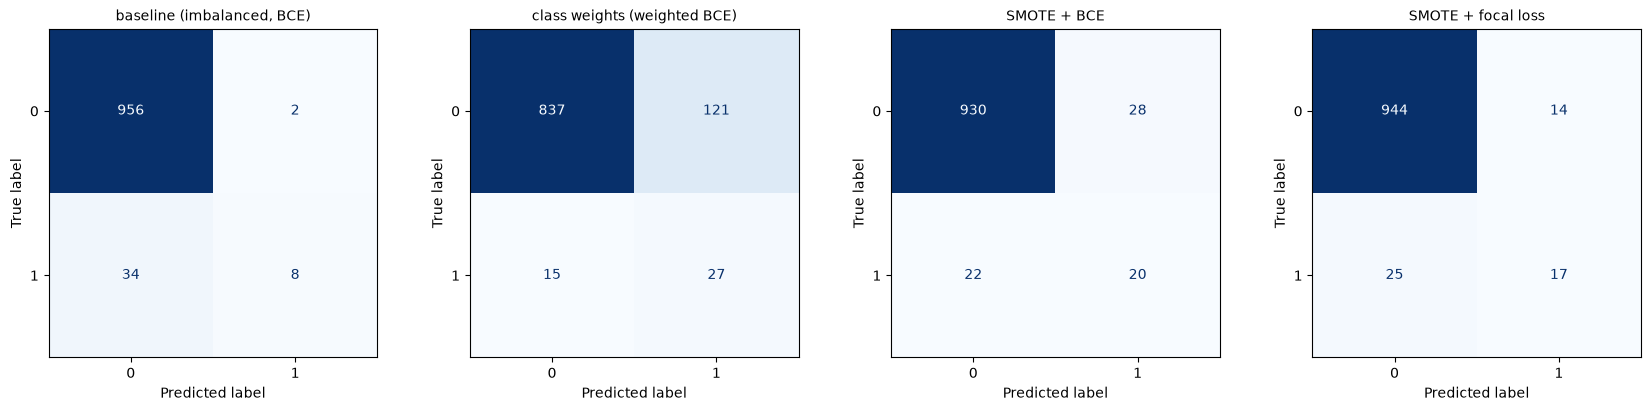

minority cases in the test set: 42


In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
show = ["baseline (imbalanced, BCE)", "class weights (weighted BCE)", "SMOTE + BCE", "SMOTE + focal loss"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, name in zip(axes, show):
    ConfusionMatrixDisplay(confusion_matrix(y_te, imb_preds[name])).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()
print("minority cases in the test set:", int(y_te.sum()))

**My answer:** **Before balancing,** the baseline has the highest accuracy (0.964), but that number is misleading: it catches only **8 of the 42 minority cases (recall 0.190, F1 0.308)**. Predicting "class 0" for everything would already give 95.8% accuracy, so the model learned to mostly ignore the rare class. **After balancing,** SMOTE and ADASYN raised recall to 0.476 (20 of 42 caught) and F1 to 0.444 and 0.460. **SMOTE + focal loss** had the best F1 (0.466, precision 0.548, recall 0.405), because the focal loss focuses training on the hard examples and keeps more false alarms away. **Class weights** went furthest toward recall (0.643, 27 of 42 caught) but at a high cost in precision (0.182), so many normal cases were flagged, and F1 (0.284) was even below the baseline. The accuracy of every balanced model went *down* a little while the minority-class metrics went up, which shows that accuracy is the wrong metric here. In real applications such as fraud detection or medical diagnosis, a missed positive (a fraud that gets through, a disease that is not detected) usually costs far more than a false alarm. So the technique, and the decision threshold, should be chosen from the business cost of each type of error, using precision, recall, F1 or PR-AUC, not accuracy.

## Exercise 5: Model Robustness and Adversarial Training *(Exercise 4 in the Colab template)*

**As stated in the exercises**  
Objective. Improve robustness against adversarial attacks.  
Instructions. Train a model on MNIST or CIFAR 10. Generate adversarial examples using FGSM or PGD. Apply adversarial training by mixing some adversarial samples into batches. Evaluate robustness on clean and adversarial data. Write a short reflection on the importance and trade offs.

**Learning point**  
Adversarial training improves worst case robustness but can reduce clean accuracy. FGSM uses a single gradient step. PGD uses multiple steps and is stronger.

**What this cell does (PREFILLED):** loads MNIST with a channel axis, defines a small CNN (`make_mnist_cnn`) and trains a normal ("clean") model for 2 epochs. Its test accuracy on normal images is the reference.

In [19]:
# PREFILLED: just execute
from tensorflow.keras.datasets import mnist
(xn_tr, yn_tr), (xn_te, yn_te) = mnist.load_data()
xn_tr = xn_tr.astype("float32")/255.0
xn_te = xn_te.astype("float32")/255.0
xn_tr = np.expand_dims(xn_tr, -1)
xn_te = np.expand_dims(xn_te, -1)

from tensorflow.keras.utils import to_categorical
yn_tr_oh = to_categorical(yn_tr, 10)
yn_te_oh = to_categorical(yn_te, 10)

def make_mnist_cnn():
    inputs = layers.Input(shape=(28,28,1))
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    m = models.Model(inputs, outputs)
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m

tf.keras.utils.set_random_seed(7)
model_clean = make_mnist_cnn()
hist_clean = model_clean.fit(xn_tr, yn_tr_oh, validation_split=0.1, epochs=2, batch_size=128, verbose=2)
clean_acc = float(model_clean.evaluate(xn_te, yn_te_oh, verbose=0)[1])
print({"clean_test_acc": clean_acc})

Epoch 1/2


422/422 - 4s - 9ms/step - accuracy: 0.9356 - loss: 0.2136 - val_accuracy: 0.9822 - val_loss: 0.0652


Epoch 2/2


422/422 - 3s - 7ms/step - accuracy: 0.9823 - loss: 0.0571 - val_accuracy: 0.9855 - val_loss: 0.0508


{'clean_test_acc': 0.984000027179718}


**What this cell does:** implements the **Fast Gradient Sign Method (FGSM)** and **adversarial training**.
- **FGSM idea:** normal training changes the *weights* to **decrease** the loss. FGSM changes the *input image* to **increase** the loss. `tf.GradientTape` with `tape.watch(x)` gives the gradient of the loss with respect to every pixel. `tf.sign` keeps only its direction (+1 or −1), and every pixel moves by **ε = 0.2** in that direction: `x_adv = clip(x + ε · sign(grad), 0, 1)`. The change is small and spread over the whole image, but it is aimed exactly where the model is most sensitive.
- **Adversarial training:** a new model is trained for 2 epochs with a manual loop. For each batch of 128 clean images I create their FGSM versions **against the current model**, and train on clean + adversarial images together (256 images per step, with `train_on_batch`). So the model learns to classify both.
- Finally, both models are tested on clean test images and on FGSM test images made against **each model itself** (a "white-box" attack, the hardest case).

In [20]:
# To-Do: implement FGSM and adversarial training
cce = tf.keras.losses.CategoricalCrossentropy()

def fgsm(model, x, y_onehot, eps=0.2):
    x = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:          # use tf.GradientTape to get gradient of loss w.r.t inputs
        tape.watch(x)                        # track the INPUT (not only the weights)
        loss = cce(y_onehot, model(x, training=False))
    grad = tape.gradient(loss, x)            # d loss / d pixel
    x_adv = x + eps * tf.sign(grad)          # step that increases the loss
    return tf.clip_by_value(x_adv, 0.0, 1.0).numpy()   # keep valid pixel values

x_sample = xn_te[:128]
y_sample = yn_te_oh[:128]
x_adv = fgsm(model_clean, x_sample, y_sample, eps=0.2)
adv_loss, adv_acc = model_clean.evaluate(x_adv, y_sample, verbose=0)
print({"acc_on_adv_before_adv_training": float(adv_acc)})

# Now adversarial training for few epochs by mixing clean and FGSM examples
tf.keras.utils.set_random_seed(7)
model_adv = make_mnist_cnn()
rng = np.random.default_rng(7)
for epoch in range(2):
    order = rng.permutation(len(xn_tr))                       # new shuffle every epoch
    losses = []
    for i in range(0, len(order), 128):
        b = order[i:i + 128]
        xb, yb = xn_tr[b], yn_tr_oh[b]
        xb_adv = fgsm(model_adv, xb, yb, eps=0.2)             # attack the CURRENT model
        out = model_adv.train_on_batch(np.concatenate([xb, xb_adv]), np.concatenate([yb, yb]))
        losses.append(out[0] if isinstance(out, (list, tuple)) else out)
    print(f"adversarial training epoch {epoch+1}: mean loss {np.mean(losses):.4f}")

adv_clean = float(model_adv.evaluate(xn_te, yn_te_oh, verbose=0)[1])
x_adv_test = fgsm(model_adv, xn_te[:1000], yn_te_oh[:1000], eps=0.2)
adv_adv = float(model_adv.evaluate(x_adv_test, yn_te_oh[:1000], verbose=0)[1])
x_adv_test_clean_model = fgsm(model_clean, xn_te[:1000], yn_te_oh[:1000], eps=0.2)
clean_adv = float(model_clean.evaluate(x_adv_test_clean_model, yn_te_oh[:1000], verbose=0)[1])
print({"clean_model_clean_acc": clean_acc, "clean_model_adv_acc (1000 imgs)": clean_adv})
print({"adv_trained_clean_acc": adv_clean, "adv_trained_adv_acc": adv_adv})

{'acc_on_adv_before_adv_training': 0.3671875}


adversarial training epoch 1: mean loss 0.4309


adversarial training epoch 2: mean loss 0.1783


{'clean_model_clean_acc': 0.984000027179718, 'clean_model_adv_acc (1000 imgs)': 0.33899998664855957}
{'adv_trained_clean_acc': 0.9815999865531921, 'adv_trained_adv_acc': 0.953000009059906}


**What this cell does:** an extra robustness curve. It measures both models' accuracy on the first 1,000 test images attacked with different strengths ε (0 = no attack), always attacking the model being tested.

         clean model  adversarially trained
epsilon                                    
0.00           0.978                  0.978
0.05           0.920                  0.930
0.10           0.795                  0.894
0.15           0.579                  0.938
0.20           0.339                  0.953
0.25           0.174                  0.904
0.30           0.080                  0.770


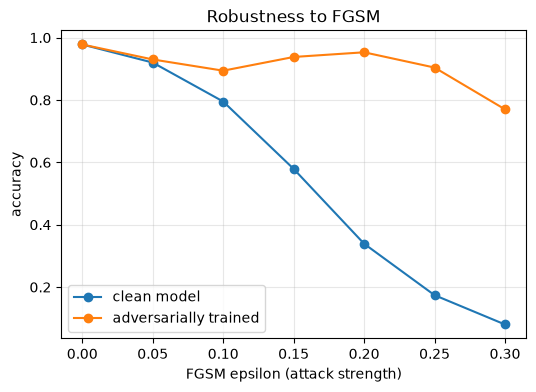

In [21]:
eps_list = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
curve = {"clean model": [], "adversarially trained": []}
for e in eps_list:
    for name, mdl in [("clean model", model_clean), ("adversarially trained", model_adv)]:
        xa = xn_te[:1000] if e == 0 else fgsm(mdl, xn_te[:1000], yn_te_oh[:1000], eps=e)
        curve[name].append(float(mdl.evaluate(xa, yn_te_oh[:1000], verbose=0)[1]))
rob_df = pd.DataFrame(curve, index=pd.Index(eps_list, name="epsilon"))
print(rob_df.round(3).to_string())
plt.figure(figsize=(6, 4))
for name, accs in curve.items():
    plt.plot(eps_list, accs, marker="o", label=name)
plt.xlabel("FGSM epsilon (attack strength)"); plt.ylabel("accuracy"); plt.title("Robustness to FGSM")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**To-Do:** Show a few clean vs adversarial images side by side and comment on perceptibility. Reflect on the trade off between clean and robust accuracy.

**What this cell does:** shows 6 test digits (top), their FGSM versions at ε = 0.2 against the clean model (middle), and the difference between the two images (bottom), with the clean model's prediction on each.

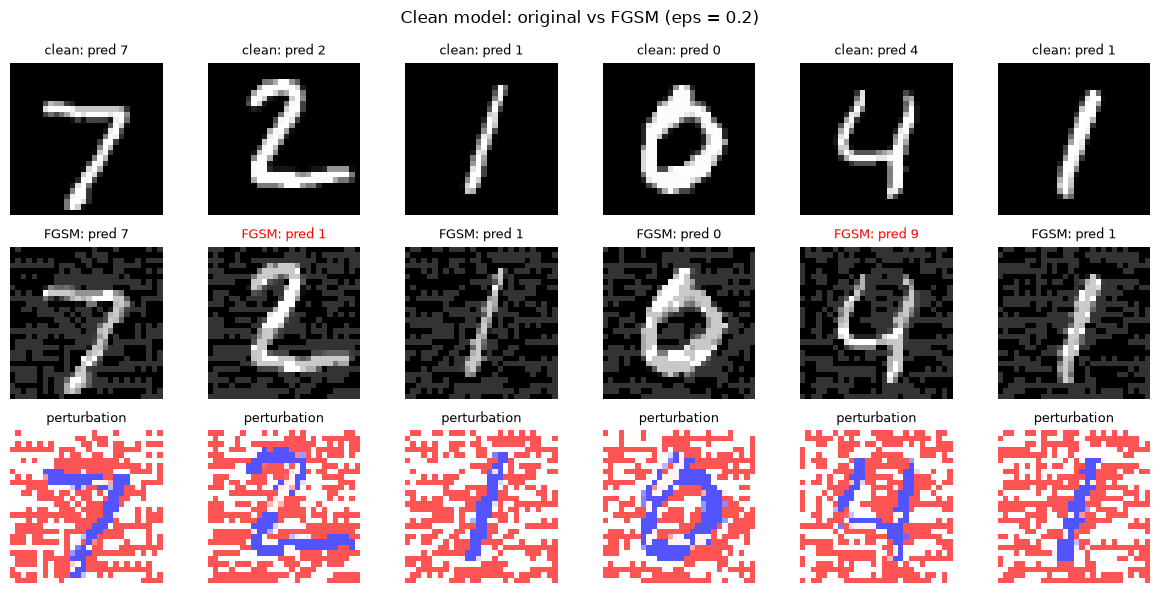

In [22]:
pred_clean = model_clean.predict(xn_te[:6], verbose=0).argmax(1)
pred_adv = model_clean.predict(x_adv_test_clean_model[:6], verbose=0).argmax(1)
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.subplot(3, 6, i + 1); plt.imshow(xn_te[i, :, :, 0], cmap="gray"); plt.axis("off")
    plt.title(f"clean: pred {pred_clean[i]}", fontsize=9)
    plt.subplot(3, 6, 6 + i + 1); plt.imshow(x_adv_test_clean_model[i, :, :, 0], cmap="gray"); plt.axis("off")
    plt.title(f"FGSM: pred {pred_adv[i]}", fontsize=9, color="red" if pred_adv[i] != yn_te[i] else "black")
    plt.subplot(3, 6, 12 + i + 1); plt.imshow(x_adv_test_clean_model[i, :, :, 0] - xn_te[i, :, :, 0], cmap="bwr", vmin=-0.3, vmax=0.3)
    plt.axis("off"); plt.title("perturbation", fontsize=9)
plt.suptitle("Clean model: original vs FGSM (eps = 0.2)"); plt.tight_layout(); plt.show()

**My answer:** **Perceptibility:** at ε = 0.2 the perturbation is clearly visible on MNIST as a grey "static" pattern over the black background, but a human still reads every digit correctly at once. The clean model, however, changed its answer on 2 of the 6 examples shown (2 → 1 and 4 → 9), and on the first 1,000 test images its accuracy fell from **98.4% to 33.9%**. Even ε = 0.1, which is much less visible, already brings it down to 79.5%.

**Effect of adversarial training:** the adversarially trained model keeps almost the same clean accuracy (**98.2% vs 98.4%**, a cost of only 0.2 points here) and reaches **95.3% on FGSM images at ε = 0.2** (vs 33.9% for the clean model). It also holds up at ε = 0.3 (77.0% vs 8.0%). One honest caveat: its accuracy is *higher* at ε = 0.15–0.2 than at ε = 0.1 (89.4%). This is a known side effect of training against a single-step attack with one fixed ε. The model partly learns to recognize the specific FGSM pattern ("label leaking" / gradient masking) instead of becoming truly robust, so a stronger multi-step attack like PGD would probably score lower.

**Reflection:** robustness matters wherever someone may try to fool a model on purpose, such as spam and fraud filters, face recognition, malware detection or self-driving perception, and also for normal noise and distribution shift. The trade-offs are that adversarial training costs more compute (here every batch needed an extra gradient pass and twice the training data), on harder datasets like CIFAR-10 it usually lowers clean accuracy noticeably, and it mainly protects against the attack type and strength it was trained on. Robust accuracy should therefore always be reported next to clean accuracy, and tested with stronger attacks than the one used in training.

![image.png](https://github.com/user-attachments/assets/44bebe22-845f-4d6e-b27b-2d687adf95f7)

## Conclusion

You applied advanced optimization, generative modeling, reinforcement learning, handling of class imbalance, and adversarial robustness. These exercises connect to real production concerns such as stability, data scarcity, safety, and fairness. Extend by adding cosine warm restarts, diffusion models, PPO with generalized advantage estimation, cost sensitive calibration on imbalanced data, and PGD adversarial training.